In [1]:
import pandas as pd
import joblib

train_df = pd.read_parquet('../data/train.parquet')
test_df = pd.read_parquet('../data/test.parquet')
feature_cols = [c for c in train_df.columns if c not in ['visit', 'treatment_flag', 'spend']]

X_train, y_train, t_train = train_df[feature_cols], train_df['visit'], train_df['treatment_flag']
X_test = test_df[feature_cols]

t_learner = joblib.load('../models/t_learner.pkl')
uplift_t = t_learner.predict(X_test)

print(X_train.shape, X_test.shape)

(29885, 11) (12808, 11)


In [2]:
from sklift.models import SoloModel
from xgboost import XGBClassifier

solo_estimator = XGBClassifier(random_state=42, eval_metric='logloss')
s_learner = SoloModel(solo_estimator)
s_learner = s_learner.fit(X_train, y_train, t_train)

In [3]:
uplift_s = s_learner.predict(X_test)
print(uplift_s[:10])

[ 0.07534473 -0.03576055 -0.00841968  0.04456951 -0.00268112  0.06963433
  0.10680928  0.09975415 -0.02155659  0.02581127]


--- T-LEARNER ---
Mean: 0.0496  Min: -0.6368  Max: 0.7848  %neg: 30.15%

--- S-LEARNER ---
Mean: 0.0490  Min: -0.3756  Max: 0.5667  %neg: 19.32%


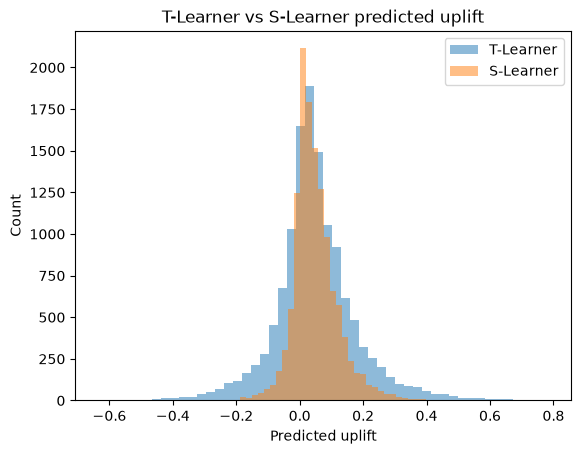

In [4]:
import matplotlib.pyplot as plt

print("--- T-LEARNER ---")
print(f"Mean: {uplift_t.mean():.4f}  Min: {uplift_t.min():.4f}  Max: {uplift_t.max():.4f}  %neg: {(uplift_t < 0).mean():.2%}")
print("\n--- S-LEARNER ---")
print(f"Mean: {uplift_s.mean():.4f}  Min: {uplift_s.min():.4f}  Max: {uplift_s.max():.4f}  %neg: {(uplift_s < 0).mean():.2%}")

plt.hist(uplift_t, bins=50, alpha=0.5, label='T-Learner')
plt.hist(uplift_s, bins=50, alpha=0.5, label='S-Learner')
plt.xlabel('Predicted uplift')
plt.ylabel('Count')
plt.title('T-Learner vs S-Learner predicted uplift')
plt.legend()
plt.show()

In [5]:
import joblib
joblib.dump(s_learner, '../models/s_learner.pkl')
joblib.dump(solo_estimator, '../models/s_learner_base_estimator.pkl')

['../models/s_learner_base_estimator.pkl']

**Qualitative comparison.** Both models agree closely on the aggregate effect (T-Learner mean 0.0496, S-Learner mean 0.0490), both tracking 03_ab_test's observed 4.52pp lift. Where they diverge is the spread; the S-Learner's distribution is visibly narrower (max 0.57 vs. 0.78, 19.3% negative vs. 30.2%), consistent with the known S-Learner shrinkage pattern predicted from 07_baseline_model's feature importances, where `treatment` ranked below `womens` and `newbie`. This narrower spread is not evidence the S-Learner is better; it's exactly as consistent with the S-Learner correctly denoising the T-Learner's estimates as it is with the S-Learner underweighting real treatment-effect heterogeneity.